# Google Trends — intensidade de busca por apostas

Medida de **exposição às bets por UF e mês**, gerada por `src/exposicao/google_trends.py`:

```bash
uv run python -m src.exposicao.google_trends              # 1 amostra
uv run python -m src.exposicao.google_trends --amostras 3 # média de 3 amostras (menos ruído)
```

A análise principal (endividamento, inadimplência, consumo, saúde mental) está em `analise.ipynb`.
As decisões gerais (período, pandemia, choques) valem aqui também e estão explicadas lá.


In [1]:
import sys
from pathlib import Path

# Raiz do projeto = primeira pasta acima (ou igual) ao cwd que tenha pyproject.toml.
# Funciona rodando da raiz ou de notebooks/ (o Jupyter/VS Code usa a pasta do notebook como cwd).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from src.config import CHOQUES, COPAS, HOJE, PANDEMIA, PROCESSED

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def carregar(nome: str) -> pl.DataFrame | None:
    p = PROCESSED / f"{nome}.parquet"
    if not p.exists():
        print(f"⚠ {p.relative_to(ROOT)} não existe — rode o script correspondente em src/")
        return None
    return pl.read_parquet(p)


def em_pandemia(col: str = "data") -> pl.Expr:
    ini, fim = (pl.lit(d).str.to_date() for d in PANDEMIA)
    return pl.col(col).is_between(ini, fim)


def marcar_choques(ax, desde="2018-01-01"):
    if PANDEMIA[1] >= desde:
        ini, fim = pl.Series(PANDEMIA).str.to_date()
        ax.axvspan(max(ini, pl.Series([desde]).str.to_date()[0]), fim, color="gray", alpha=0.15, lw=0)
        ax.text(fim, 0.02, "pandemia ", ha="right", va="bottom", fontsize=7, color="dimgray",
                transform=ax.get_xaxis_transform())
    for rotulo, (ini, fim) in COPAS.items():
        if fim >= desde:
            ini, fim = pl.Series([ini, fim]).str.to_date()
            ax.axvspan(ini, fim, color="goldenrod", alpha=0.25, lw=0)
            ax.text(ini, 0.02, rotulo + " ", rotation=90, ha="right", va="bottom", fontsize=7,
                    color="darkgoldenrod", transform=ax.get_xaxis_transform())
    for d, rotulo in CHOQUES.items():
        if d >= desde:
            x = pl.Series([d]).str.to_date()[0]
            ax.axvline(x, color="crimson", ls="--", lw=0.8, alpha=0.7)
            ax.text(x, 1.0, " " + rotulo, rotation=90, va="top", ha="right", fontsize=7,
                    color="crimson", transform=ax.get_xaxis_transform())

## Como ler os gráficos

**Linhas vermelhas tracejadas** marcam os marcos regulatórios das bets (definidos em `src/config.py::CHOQUES`):

| Data | Marco | Por que importa |
|---|---|---|
| 12/dez/2018 | Lei 13.756 | Cria as apostas de quota fixa, mas sem regulamentação. As bets passam a operar do exterior |
| 29/dez/2023 | Lei 14.790 | Regulamenta o setor (tributação, regras de publicidade, autorização) |
| 1º/out/2024 | Bloqueio de sites não autorizados | Saem do ar as bets que não pediram autorização. Vedado o uso de recursos do Bolsa Família |
| 1º/jan/2025 | Mercado regulado | Só operam empresas autorizadas pela SPA/MF |
| 25/set/2026 | MP 1.394 | **Proíbe as bets**: depósitos vetados de imediato, saques até 05/10, sites fora do ar em 06/10 |

**Faixas douradas** são as Copas do Mundo masculinas (2018: 14/jun–15/jul; 2022: 20/nov–18/dez;
2026: 11/jun–19/jul; `src/config.py::COPAS`). Copa é o maior evento de apostas esportivas, então as buscas sobem
mesmo sem nenhuma mudança regulatória. A de 2026 terminou dois meses antes da MP 1.394 e infla o período pré-MP.

**Faixa cinza** é o período da pandemia (mar/2020–dez/2021, `src/config.py::PANDEMIA`). Nele as séries são
afetadas por fatores próprios. Para as buscas, isso inclui mais tempo em casa e online e o futebol parado e depois
sem público. Por isso o crescimento desse período não deve ser lido como efeito das bets. A justificativa da janela
está no `analise.ipynb`.

As linhas são **referência visual**, não resultado. A coincidência entre uma linha e uma mudança na série não
prova causalidade, porque outros eventos podem cair no mesmo mês.


## Decisões e limitações

Gerado por `src/exposicao/google_trends.py`. É a única medida de **intensidade de bets por UF e mês**
disponível hoje, enquanto não há dados oficiais de gasto por UF.

**Decisão — termo:** cesta `bet + apostas + betano + bet365 + tigrinho` (OR). O Google não tem um tópico estável de
"apostas online" no Brasil (as sugestões são apps e marcas soltas). Um termo só perde quem busca direto a marca ou
o cassino online ("tigrinho"). "bet" sozinho também pega buscas em inglês. A cesta dilui esse ruído.

**Decisão — comparabilidade entre UFs:** cada série por UF vem do Google normalizada em 0–100 *dentro* da UF.
Usamos o ranking entre UFs do período inteiro (`interest_by_region`, 100 = UF com maior participação) e reescalamos
cada série para que sua média seja esse nível: `comparavel = serie / média(serie) × nível_UF`.

**Limitações:**
- É **participação** (buscas do termo / total de buscas da UF), não volume absoluto nem gasto.
- O Google trabalha com **amostras**, então os valores mudam um pouco entre execuções (`--amostras N` tira a média de N).
- O último mês é parcial e é **descartado**, como no Pix.
- Busca ≠ aposta. Depois que o hábito se forma, as pessoas entram direto no app sem buscar. A queda depois de 2023
  pode ser parcialmente isso e não menos apostas. Por isso o Trends serve melhor para **variação entre UFs** e
  **choques abruptos** (como a MP) do que para tendência de longo prazo.


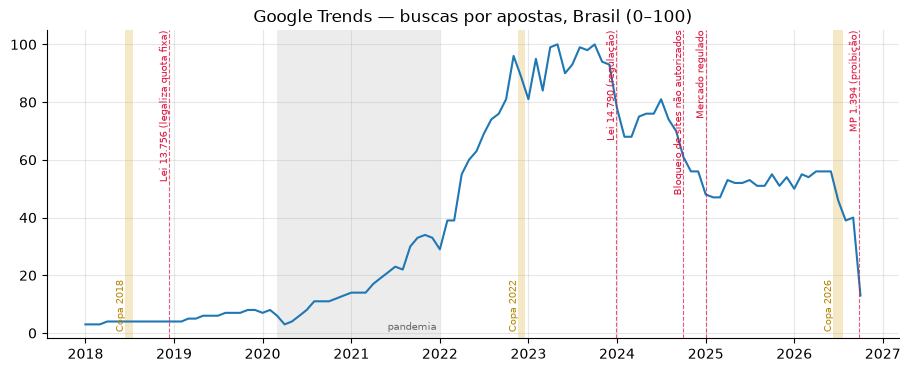

In [2]:
gt = carregar("google_trends_uf")
if gt is not None:
    gt = gt.filter(pl.col("data") < pl.date(HOJE.year, HOJE.month, 1))
    br_gt = gt.filter(pl.col("uf") == "BR").sort("data")
    fig, ax = plt.subplots()
    ax.plot(br_gt["data"], br_gt["indice"])
    marcar_choques(ax); ax.set_title("Google Trends — buscas por apostas, Brasil (0–100)")


**Leitura:** as buscas crescem a partir de 2021, têm pico em 2023 e caem depois. Em out/2026, primeiro mês cheio
depois da MP 1.394, o índice despenca (~40 → ~13). É a evidência mais direta até agora de que a proibição pegou na
demanda. O pico em jun/2026 coincide com a Copa do Mundo.


uf,pre,pos,var_pct,trends_2024
str,f64,f64,f64,f64
"""CE""",53.666667,11.0,-79.5,99.135769
"""AM""",48.0,10.0,-79.2,161.877682
"""RJ""",37.666667,8.0,-78.8,130.664858
"""PA""",52.0,11.0,-78.8,107.409937
"""MA""",50.0,11.0,-78.0,130.182176
…,…,…,…,…
"""ES""",41.0,13.0,-68.3,101.132833
"""RS""",50.333333,16.0,-68.2,60.352965
"""DF""",45.0,16.0,-64.4,70.383374


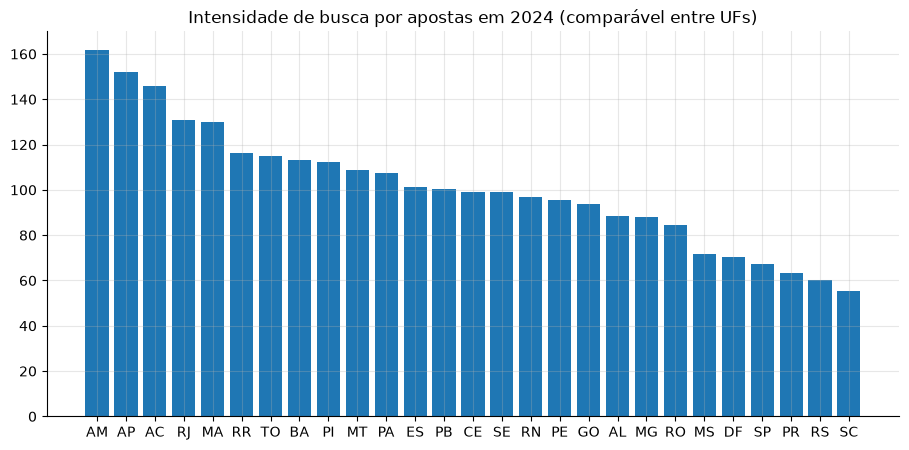

In [3]:
if gt is not None:
    uf_gt = gt.filter(pl.col("uf") != "BR")
    nivel_2024 = (uf_gt.filter(pl.col("data").dt.year() == 2024).group_by("uf")
                  .agg(pl.col("indice_comparavel").mean().alias("trends_2024")).sort("trends_2024", descending=True))
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(nivel_2024["uf"], nivel_2024["trends_2024"]); ax.set_title("Intensidade de busca por apostas em 2024 (comparável entre UFs)")

    def media(ini, fim):
        return pl.col("indice").filter(pl.col("data").is_between(pl.date(*ini, 1), pl.date(*fim, 1))).mean()
    queda = (uf_gt.group_by("uf").agg(media((2026, 6), (2026, 8)).alias("pre"), media((2026, 10), (2026, 10)).alias("pos"))
             .with_columns(((pl.col("pos") / pl.col("pre") - 1) * 100).round(1).alias("var_pct"))
             .join(nivel_2024, on="uf").sort("var_pct"))
    display(queda)


**Decisão — janela da queda por UF:** a média de jun–ago/2026 (pré-MP) é comparada com out/2026. Pegamos três
meses no pré porque as séries por UF são ruidosas (amostragem do Google). Setembro fica fora porque está contaminado
(MP em 25/09). Jun/2026 teve Copa, o que infla o pré e torna a queda medida um **limite superior**.

**Para que serve:** `trends_2024` (nível pré-tratamento por UF) é a medida de exposição para cruzar com SCR,
PMC/PMS e DATASUS agregado por UF. É medida em 2024, depois da pandemia e antes da vedação do PBF e da regulação,
seguindo as decisões da seção da pandemia.
